In [165]:
import numpy as np
import pandas as pd
import seaborn as sns
import missingno as msno
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import shapiro


from sklearn.datasets import load_breast_cancer
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer #transform a column in the pipeline
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold #cross validation 
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    MinMaxScaler,
    PolynomialFeatures,
    FunctionTransformer
)
from sklearn.model_selection import GridSearchCV

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import mean_absolute_error, accuracy_score
from imblearn import FunctionSampler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_absolute_error, accuracy_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import make_scorer, f1_score



sns.set(style="whitegrid", color_codes=True)

RSEED = 10

In [74]:
# Import data 
df_train = pd.read_csv('data/Train.csv')
df_train.head()

,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


In [75]:
# Check for missing data
df_train.isnull().sum()

country                   0
year                      0
uniqueid                  0
bank_account              0
location_type             0
cellphone_access          0
household_size            0
age_of_respondent         0
gender_of_respondent      0
relationship_with_head    0
marital_status            0
education_level           0
job_type                  0
dtype: int64

In [76]:
# Find rows with any 0 values
rows_with_zeros = df_train[(df_train == 0).any(axis=1)]
print(rows_with_zeros)

Empty DataFrame
Columns: [country, year, uniqueid, bank_account, location_type, cellphone_access, household_size, age_of_respondent, gender_of_respondent, relationship_with_head, marital_status, education_level, job_type]
Index: []


In [77]:
df_train[df_train['year']==0]

,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type


In [78]:
df_train.describe().T

,count,mean,std,min,25%,50%,75%,max
year,23524.0,2016.975939,0.847371,2016.0,2016.0,2017.0,2018.0,2018.0
household_size,23524.0,3.797483,2.227613,1.0,2.0,3.0,5.0,21.0
age_of_respondent,23524.0,38.805220,16.520569,16.0,26.0,35.0,49.0,100.0


In [79]:
df_train.nunique()

country                      4
year                         3
uniqueid                  8735
bank_account                 2
location_type                2
cellphone_access             2
household_size              20
age_of_respondent           85
gender_of_respondent         2
relationship_with_head       6
marital_status               5
education_level              6
job_type                    10
dtype: int64

In [80]:
df_train.shape

(23524, 13)

In [81]:
def analyze_data(df, y):
    """
    Perform comprehensive data inspection including displaying data, descriptive statistics, 
    checking for duplicates, missing values, plotting target variable, and detecting outliers.

    Parameters:
    df (pd.DataFrame): The input DataFrame to inspect.
    y (pd.Series): The target variable Series.

    Returns:
    None: This function displays various insights and visualizations about the dataset.

    """
    print("Display some values from the dataframe:")
    display(df.head())
    print("-"*10)
    print(f"Dataframe Shape: {df.shape}")
    print("-"*10)
    print("Dataframe Descriptive Statistics:")
    display(df.describe().T)
    print("-"*10)
    print("Unique values from each column:")
    print(df.nunique())
    print("-"*10)
    check_duplicates(df)
    print("-"*10)
    # Plot the missing values
    plot_missing_values(df)
    print("-"*10)
    # Print percentages of missing values 
    print(percentage_of_missing_values(df))
    print("-"*10)
    # Plot the target variable
    plot_target_variable(y)
    print("-"*10)
    print(f"Checking for data imbalance:\n{y.value_counts()}")
    print("-"*10)
    # Check for outliers
    detect_outliers(df, y)

Display some values from the dataframe:


,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,1,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,0,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,1,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,0,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,0,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


----------
Dataframe Shape: (23524, 13)
----------
Dataframe Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
year,23524.0,2016.975939,0.847371,2016.0,2016.0,2017.0,2018.0,2018.0
bank_account,23524.0,0.140792,0.347815,0.0,0.0,0.0,0.0,1.0
household_size,23524.0,3.797483,2.227613,1.0,2.0,3.0,5.0,21.0
age_of_respondent,23524.0,38.805220,16.520569,16.0,26.0,35.0,49.0,100.0


----------
Unique values from each column:
country                      4
year                         3
uniqueid                  8735
bank_account                 2
location_type                2
cellphone_access             2
household_size              20
age_of_respondent           85
gender_of_respondent         2
relationship_with_head       6
marital_status               5
education_level              6
job_type                    10
dtype: int64
----------
Checking for duplicates
No duplicates found !!!
----------


/Users/marenklan/Desktop/spiced/ds-ml-project/.venv/lib/python3.11/site-packages/missingno/missingno.py:61: UserWarning: Plotting a sparkline on an existing axis is not currently supported. To remove this warning, set sparkline=False.
  warnings.warn(


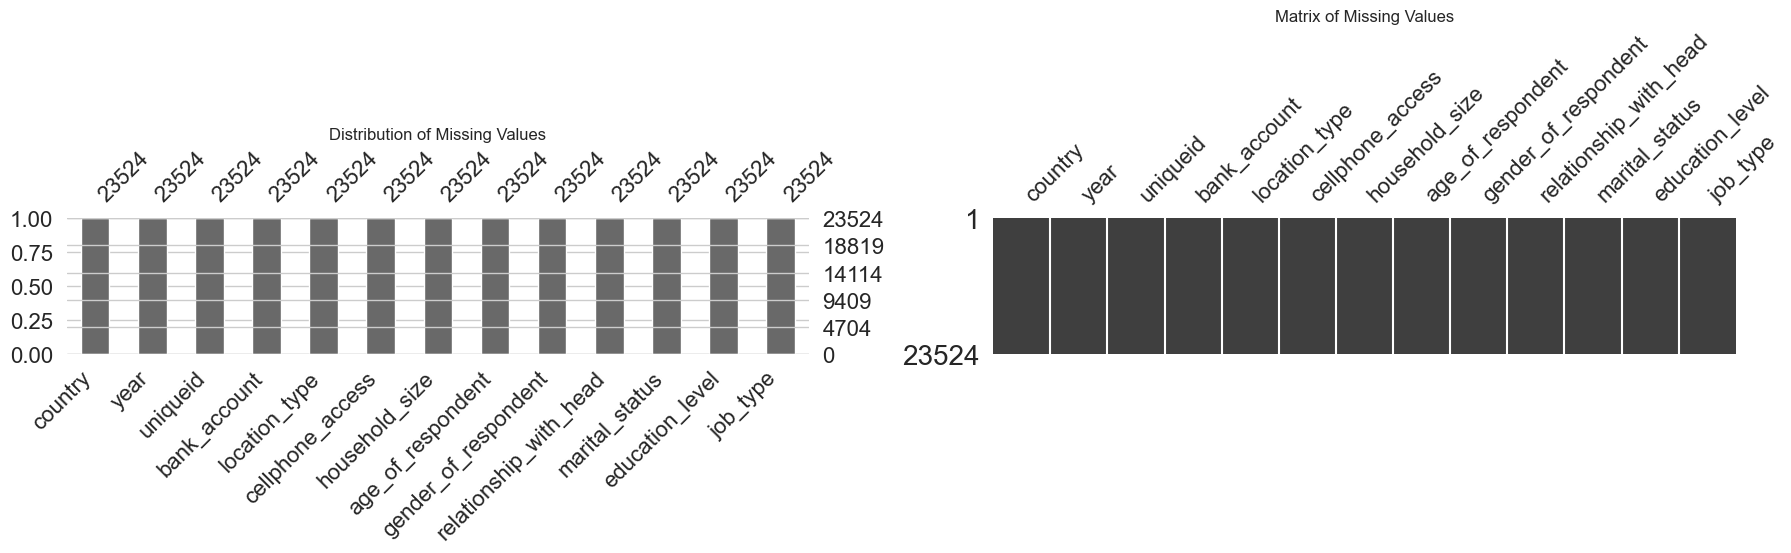

----------
Percentage of missing values per column:
country                   0.0
year                      0.0
uniqueid                  0.0
bank_account              0.0
location_type             0.0
cellphone_access          0.0
household_size            0.0
age_of_respondent         0.0
gender_of_respondent      0.0
relationship_with_head    0.0
marital_status            0.0
education_level           0.0
job_type                  0.0
dtype: float64
----------
Plotting the target variable


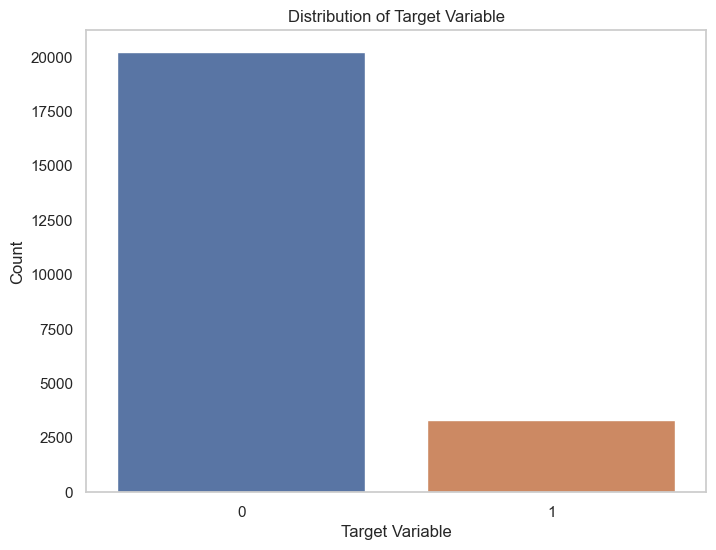

----------
Checking for data imbalance:
bank_account
0    20212
1     3312
Name: count, dtype: int64
----------
Checking for outliers


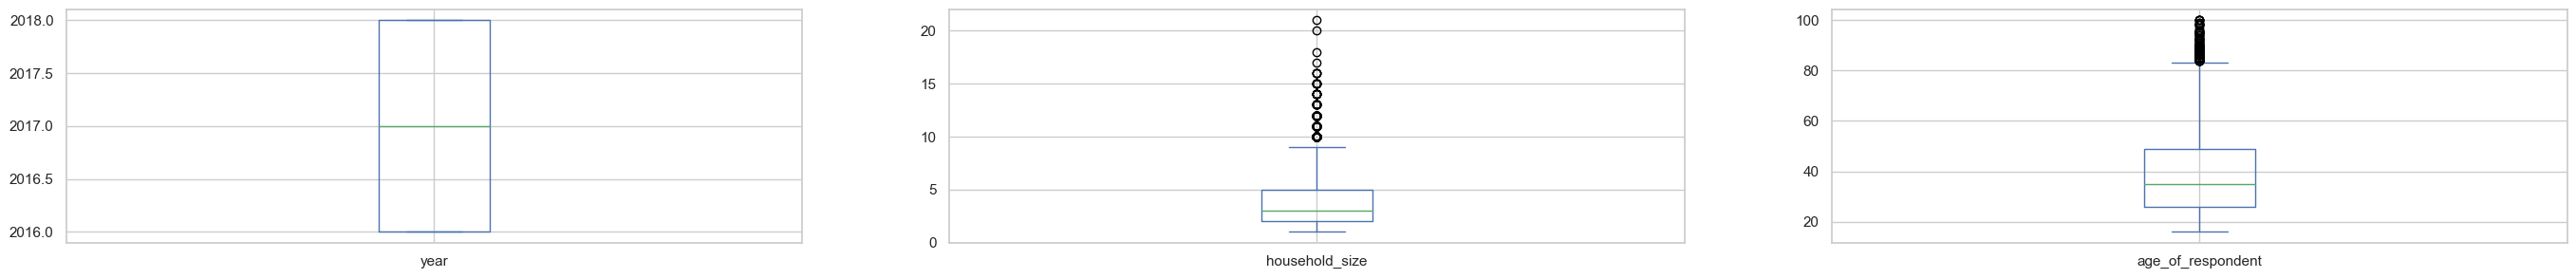

In [90]:
analyze_data(df_train, df_train['bank_account'])

In [89]:
def plot_missing_values(df):
    """
    Plot missing values in the DataFrame and show percentage of missing values per column.

    Parameters:
    df (pd.DataFrame): The input DataFrame to plot missing values.

    Returns:
    None: This function plots the missing value distribution and prints the percentage of missing values per column.
    """
    fig, axs = plt.subplots(1, 2, figsize=(18, 6))  # Increase figsize for more space
    
    # Plotting missing value bar chart
    axs[0].set_title("Distribution of Missing Values")
    msno.bar(df, ax=axs[0])
    
    # Plotting missing value matrix
    axs[1].set_title("Matrix of Missing Values")
    msno.matrix(df, ax=axs[1])
    
    plt.tight_layout(rect=[0, 0, 1, 0.95])  # Adjust layout to prevent overlapping
    plt.show()

def percentage_of_missing_values(df):
    # Calculate the percentage of missing values per column
    missing_values_count = df.isna().sum()
    total_values = df.shape[0]  # Total number of rows in the DataFrame
    percentage_missing_values = (missing_values_count / total_values) * 100
    # Display the percentages of missing values per column
    print("Percentage of missing values per column:")
    return(percentage_missing_values)


def plot_target_variable(y):
    """
    Plot the distribution of the target variable.

    Parameters:
    y (pd.Series): The target variable Series to plot.

    Returns:
    None: This function plots the distribution of the target variable.
    """
    print("Plotting the target variable")
    # Plot the target variable separately
    plt.figure(figsize=(8, 6))
    sns.countplot(x=y)
    plt.title("Distribution of Target Variable")
    plt.xlabel("Target Variable")
    plt.ylabel("Count")
    plt.grid(False)
    plt.show()
    

def check_duplicates(data):
    """
    Check for duplicates in a DataFrame.

    Parameters:
    data (pd.DataFrame): The DataFrame to check for duplicates.

    Returns:
    None: Prints the number of duplicates found if any, otherwise prints "No duplicates found !!!".
    """
    print("Checking for duplicates")
    has_dup = data.duplicated()
    true_dup = np.where(has_dup == True)
    if len(true_dup[0]) > 0:
        print("Data has", len(true_dup[0]), "duplicates")
    else:
        print("No duplicates found !!!")

def detect_outliers(df, y):
    """
    Detect outliers in the DataFrame features.

    Parameters:
    df (pd.DataFrame): The input DataFrame to detect outliers.
    y (pd.Series): The target variable Series.

    Returns:
    None: This function plots boxplots for each feature in the DataFrame to detect outliers.
    """
    print("Checking for outliers")
    feature_list = df.columns.tolist()
    feature_list.remove(y.name)
    df_outliers = df[feature_list].copy()
    df_outliers.plot(kind='box', subplots=True, layout=(8,3), figsize=(34,30))
    plt.show()

def fill_missing_values(df, missing_dict):
    """
    Fill missing values in DataFrame columns based on specified methods.

    Parameters:
    df (pd.DataFrame): The DataFrame containing missing values.
    missing_dict (dict): Dictionary where keys are column names with missing values
                        and values are the method to use for filling missing values.
                        Valid methods include 'mean', 'median', 'mode', 'ffill', 'bfill',
                        or a specific value (e.g., 0).

    Returns:
    pd.DataFrame: DataFrame with missing values filled based on the specified methods.
    """
    for column, method in missing_dict.items():
        if method == 'mean':
            df[column].fillna(df[column].mean(), inplace=True)
        elif method == 'median':
            df[column].fillna(df[column].median(), inplace=True)
        elif method == 'mode':
            df[column].fillna(df[column].mode()[0], inplace=True)
        elif method == 'ffill':
            df[column].fillna(method='ffill', inplace=True)
        elif method == 'bfill':
            df[column].fillna(method='bfill', inplace=True)
        else:
            df[column].fillna(method, inplace=True)  # Specific value provided

    return df

def cleaning_data(df, rename_dict=None,columns_to_drop=None,drop_duplicates=True,missing_dict=None):
    """
    Clean and preprocess a DataFrame by renaming columns, dropping specified columns,
    dropping duplicates, and filling missing values based on provided parameters.

    Parameters:
    df (pd.DataFrame): The DataFrame to be cleaned.
    rename_dict (dict, optional): Dictionary mapping old column names to new names. Default is None.
    columns_to_drop (list of str, optional): List of column names to drop. Default is None.
    drop_duplicates (bool, optional): Whether to drop duplicate rows. Default is True.
    missing_dict (dict, optional): Dictionary where keys are column names with missing values
                                   and values are the method to use for filling missing values.
                                   Valid methods include 'mean', 'median', 'mode', 'ffill', 'bfill',
                                   or a specific value. Default is None.

    Returns:
    None: Modifies the input DataFrame `df` in place.
    """
    if rename_dict is not None:
        df.rename(columns=rename_dict, inplace=True)
    if columns_to_drop is not None:
        df = df.drop(columns=columns_to_drop)
    if drop_duplicates:
        df = df.drop_duplicates()
    if missing_dict is not None:
        df= fill_missing_values(df,missing_dict)

In [88]:
duplicates = df_train[df_train['uniqueid'].duplicated(keep=False)]
print(duplicates)

      country  year       uniqueid  bank_account location_type   
0       Kenya  2018     uniqueid_1             1         Rural  \
1       Kenya  2018     uniqueid_2             0         Rural   
2       Kenya  2018     uniqueid_3             1         Urban   
3       Kenya  2018     uniqueid_4             0         Rural   
4       Kenya  2018     uniqueid_5             0         Urban   
...       ...   ...            ...           ...           ...   
23519  Uganda  2018  uniqueid_2113             0         Rural   
23520  Uganda  2018  uniqueid_2114             0         Rural   
23521  Uganda  2018  uniqueid_2115             0         Rural   
23522  Uganda  2018  uniqueid_2116             0         Urban   
23523  Uganda  2018  uniqueid_2117             0         Rural   

      cellphone_access  household_size  age_of_respondent   
0                  Yes               3                 24  \
1                   No               5                 70   
2                  Yes  

In [91]:
df_train.groupby('country')


In [92]:
# Group by 'column1'
grouped = df_train.groupby('country')

# Iterate over groups
for key, group in grouped:
    print(f"Group: {key}")
    print(group)
    print("\n")

Group: Kenya
     country  year       uniqueid  bank_account location_type   
0      Kenya  2018     uniqueid_1             1         Rural  \
1      Kenya  2018     uniqueid_2             0         Rural   
2      Kenya  2018     uniqueid_3             1         Urban   
3      Kenya  2018     uniqueid_4             0         Rural   
4      Kenya  2018     uniqueid_5             0         Urban   
...      ...   ...            ...           ...           ...   
6063   Kenya  2018  uniqueid_6067             0         Rural   
6064   Kenya  2018  uniqueid_6068             0         Urban   
6065   Kenya  2018  uniqueid_6069             0         Rural   
6066   Kenya  2018  uniqueid_6070             0         Rural   
6067   Kenya  2018  uniqueid_6071             0         Rural   

     cellphone_access  household_size  age_of_respondent gender_of_respondent   
0                 Yes               3                 24               Female  \
1                  No               5       

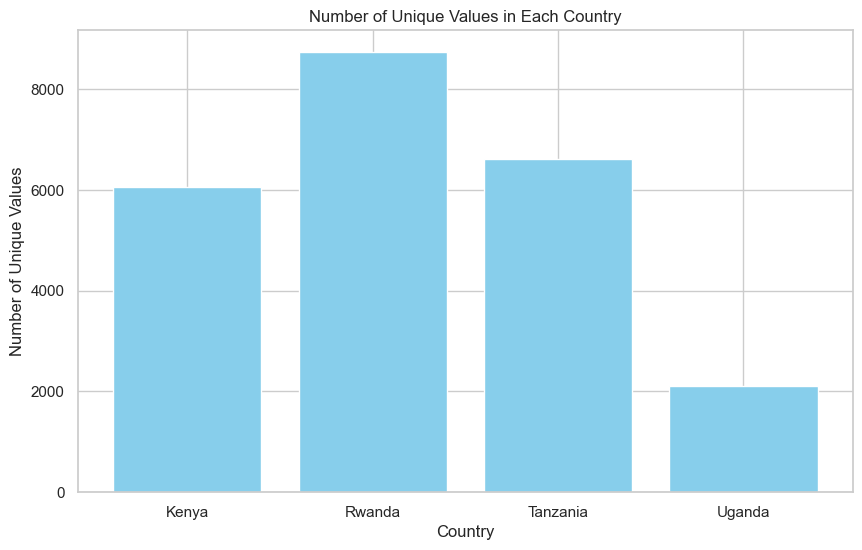

In [87]:
# Group by 'country' and count unique values in 'unique_values'
unique_counts = df_train.groupby('country')['uniqueid'].nunique().reset_index()

# Plotting
plt.figure(figsize=(10, 6))
plt.bar(unique_counts['country'], unique_counts['uniqueid'], color='skyblue')
plt.xlabel('Country')
plt.ylabel('Number of Unique Values')
plt.title('Number of Unique Values in Each Country')
plt.show()

In [ ]:
df_train['country'].value_counts()

country
Rwanda      8735
Tanzania    6620
Kenya       6068
Uganda      2101
Name: count, dtype: int64

In [84]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler

In [85]:
le = LabelEncoder()
df_train['bank_account'] = le.fit_transform(df_train['bank_account'])

In [86]:
df_train.head()

,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,1,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,0,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,1,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,0,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,0,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


In [93]:
country_names = ['Uganda', 'Kenya', 'Tanzania', 'Rwanda']
counts = []

# Loop through each country
for country_name in country_names:
    # Filter the DataFrame for the current country and bank accounts
    filtered_df = df_train[(df_train['country'] == country_name) & (df_train['bank_account'] == 1)]
    
    # Count the number of rows that match the criteria
    num_with_bank_account = filtered_df.shape[0]
    print(f"Number of people with a bank account in {country_name}: {num_with_bank_account}")
    #Append the count to the list
    counts.append(num_with_bank_account)

Number of people with a bank account in Uganda: 181
Number of people with a bank account in Kenya: 1521
Number of people with a bank account in Tanzania: 607
Number of people with a bank account in Rwanda: 1003


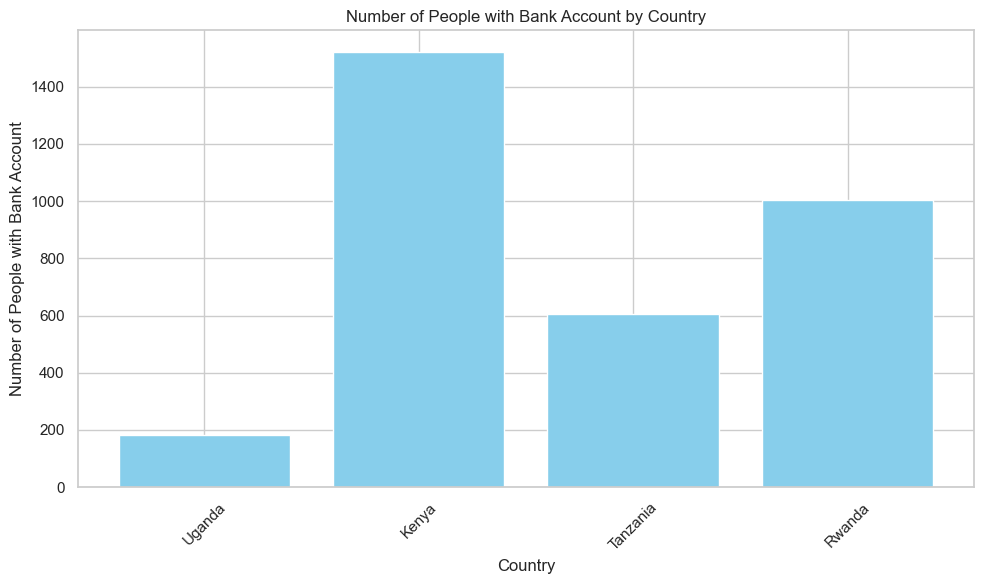

In [94]:
# Sample data (replace with your actual data)
data = {
    'country': ['Uganda', 'Kenya', 'Tanzania', 'Rwanda'],
    'num_with_bank_account': [181, 1521, 607, 1003]  # Replace with your actual counts
}

# Convert data to a DataFrame
df = pd.DataFrame(data)

# Plotting the bar chart
plt.figure(figsize=(10, 6))
plt.bar(df['country'], df['num_with_bank_account'], color='skyblue')
plt.xlabel('Country')
plt.ylabel('Number of People with Bank Account')
plt.title('Number of People with Bank Account by Country')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

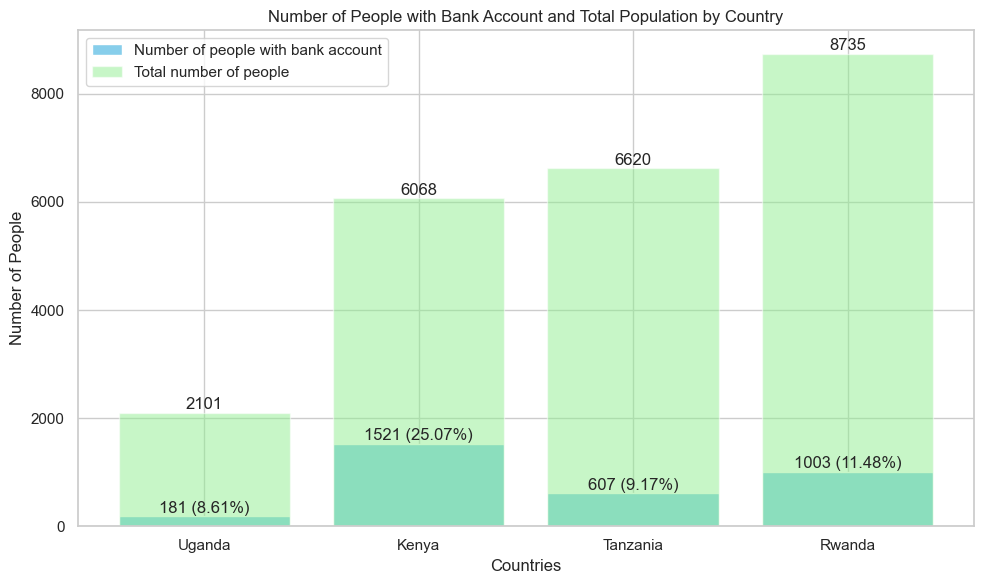

In [ ]:
# Provided data
countries = ['Uganda', 'Kenya', 'Tanzania', 'Rwanda']
bank_accounts = [181, 1521, 607, 1003]
total_population = [2101, 6068, 6620, 8735]

# Calculate the percentage of people with a bank account
percentages = [round((ba / tp) * 100, 2) for ba, tp in zip(bank_accounts, total_population)]

# Create the bar plot
fig, ax = plt.subplots(figsize=(10, 6))

# Bars for the number of people with a bank account
bars1 = ax.bar(countries, bank_accounts, color='skyblue', label='Number of people with bank account')

# Bars for the total number of people
bars2 = ax.bar(countries, total_population, color='lightgreen', alpha=0.5, label='Total number of people')

# Labels for numeric values above the bars
for bar, bank_count, total_count, percentage in zip(bars1, bank_accounts, total_population, percentages):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10, f'{bank_count} ({percentage}%)', ha='center', va='bottom')
    ax.text(bar.get_x() + bar.get_width() / 2, total_count + 10, f'{total_count}', ha='center', va='bottom')

# Add labels and title
ax.set_xlabel('Countries')
ax.set_ylabel('Number of People')
ax.set_title('Number of People with Bank Account and Total Population by Country')
ax.legend()

# Display the plot
plt.tight_layout()
plt.show()

In [95]:
# SPLIT
from sklearn.model_selection import train_test_split
X = df_train.drop(['bank_account'], axis=1)
y = df_train['bank_account']
# Identify categorical and numerical features
cat_features = list(X.select_dtypes(include=['object']).columns)
num_features = list(X.select_dtypes(exclude=['object']).columns)
# Split the 'features' and 'income' data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)
# Show the results of the split
print ("Training set has {} samples.".format(X_train.shape[0]))
print ("Testing set has {} samples.".format(X_test.shape[0]))

Training set has 18819 samples.
Testing set has 4705 samples.


In [96]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18819 entries, 22960 to 2732
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   country                 18819 non-null  object
 1   year                    18819 non-null  int64 
 2   uniqueid                18819 non-null  object
 3   location_type           18819 non-null  object
 4   cellphone_access        18819 non-null  object
 5   household_size          18819 non-null  int64 
 6   age_of_respondent       18819 non-null  int64 
 7   gender_of_respondent    18819 non-null  object
 8   relationship_with_head  18819 non-null  object
 9   marital_status          18819 non-null  object
 10  education_level         18819 non-null  object
 11  job_type                18819 non-null  object
dtypes: int64(3), object(9)
memory usage: 1.9+ MB


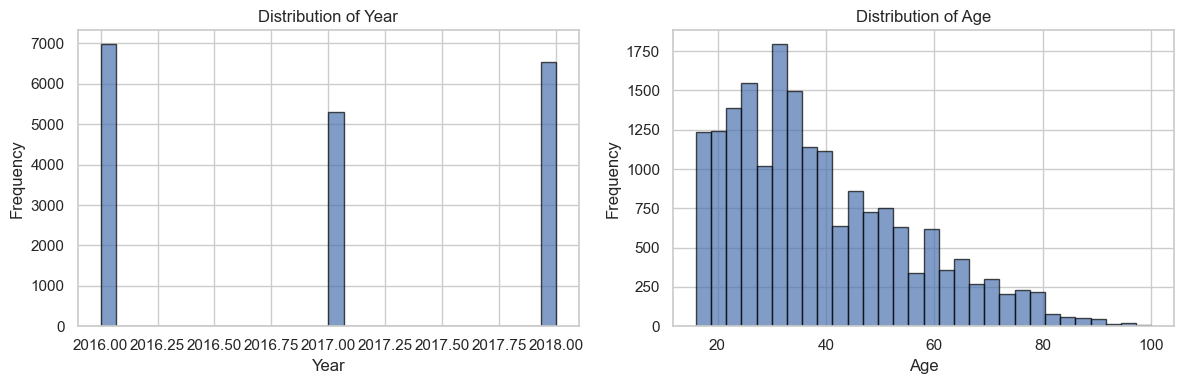

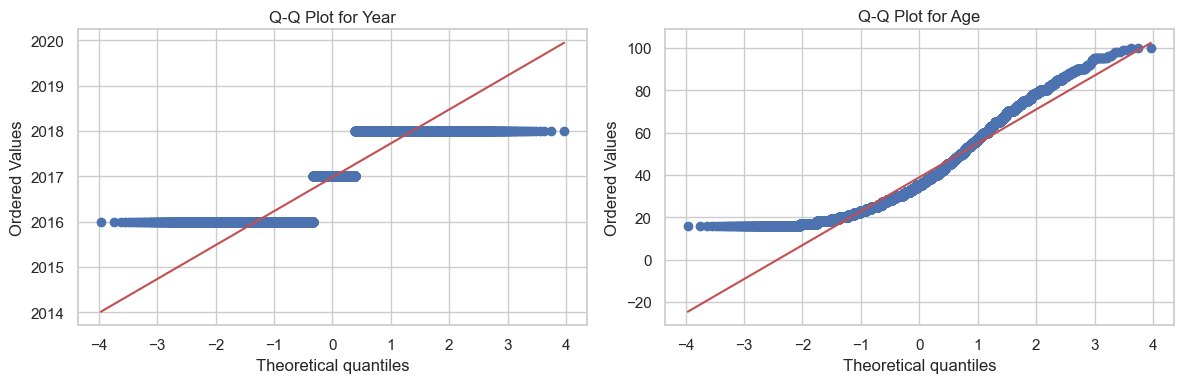

In [97]:
# Sample data (replace with your actual data)
year = X_train['year']  # Example: Normally distributed year
age = X_train['age_of_respondent']    # Example: Normally distributed age

# Plot histograms
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

axes[0].hist(year, bins=30, edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution of Year')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Frequency')

axes[1].hist(age, bins=30, edgecolor='black', alpha=0.7)
axes[1].set_title('Distribution of Age')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Q-Q plots to check normality
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

stats.probplot(year, dist="norm", plot=axes[0])
axes[0].set_title('Q-Q Plot for Year')

stats.probplot(age, dist="norm", plot=axes[1])
axes[1].set_title('Q-Q Plot for Age')

plt.tight_layout()
plt.show()

In [ ]:
# Shapiro-Wilk test for normality
year_stat, year_p_value = shapiro(year)
age_stat, age_p_value = shapiro(age)

print(f"Shapiro-Wilk Test for Year: Statistics={year_stat}, p-value={year_p_value}")
print(f"Shapiro-Wilk Test for Age: Statistics={age_stat}, p-value={age_p_value}")

# Interpret the p-values
alpha = 0.05
if year_p_value > alpha:
    print("Year is likely normally distributed (fail to reject H0)")
else:
    print("Year is not normally distributed (reject H0)")

if age_p_value > alpha:
    print("Age is likely normally distributed (fail to reject H0)")
else:
    print("Age is not normally distributed (reject H0)")

Shapiro-Wilk Test for Year: Statistics=0.7779471197984665, p-value=7.854578023442163e-94
Shapiro-Wilk Test for Age: Statistics=0.935097542601683, p-value=2.2224707777508248e-66
Year is not normally distributed (reject H0)
Age is not normally distributed (reject H0)


/Users/marenklan/Desktop/spiced/ds-ml-project/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:573: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 18819.
  res = hypotest_fun_out(*samples, **kwds)


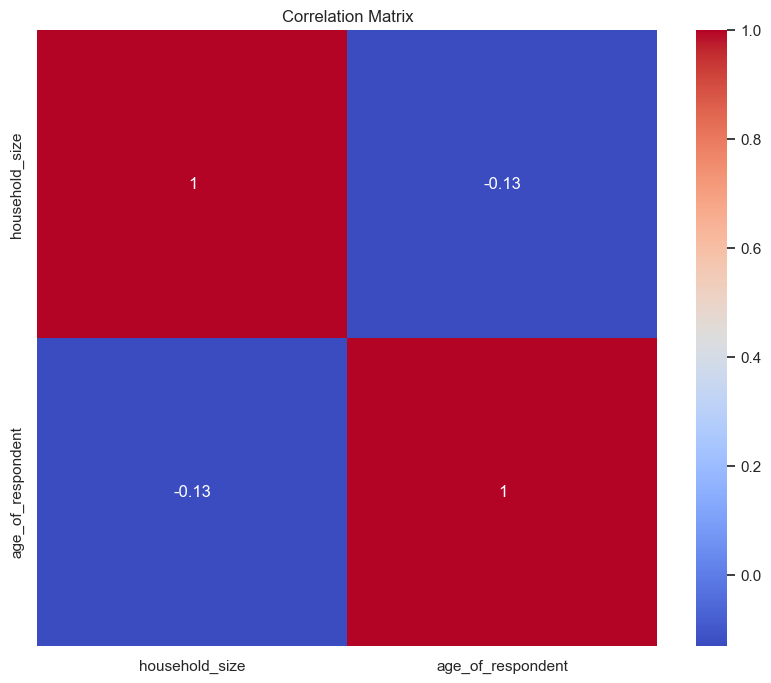

In [ ]:

# correlation matrix for numerical features 
numerical_features = ['household_size', 'age_of_respondent']
correlation_matrix = df_train[numerical_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

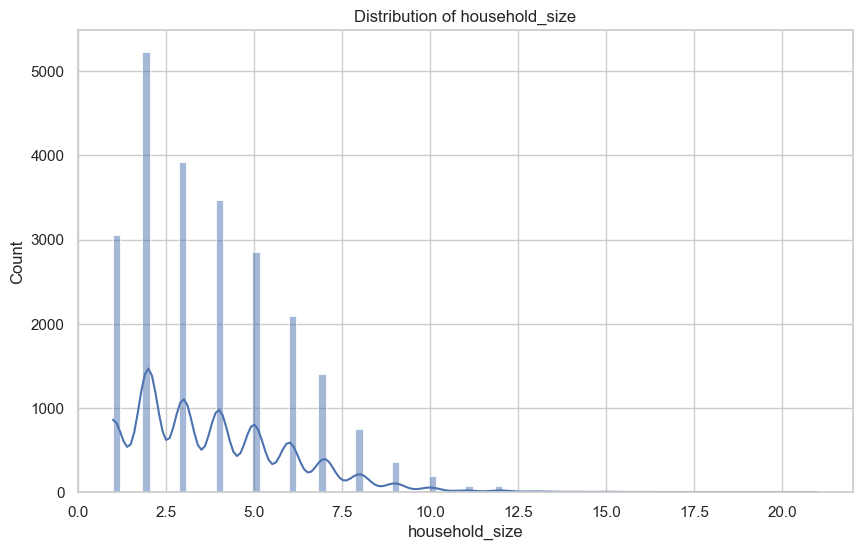

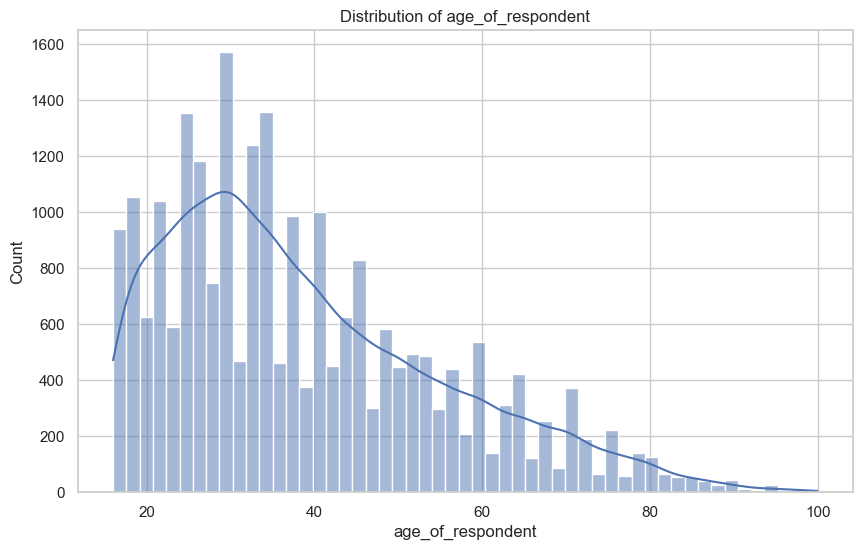

In [98]:

# overview of numerical feature distribution
for column in ['household_size', 'age_of_respondent']:
    plt.figure(figsize=(10, 6))
    sns.histplot(df_train[column], kde=True)
    plt.title(f'Distribution of {column}')
    plt.show()

In [99]:
num_transformer = Pipeline(
    steps=[
        ('scaling', MinMaxScaler()),  
    ])

In [100]:
cat_transformer = Pipeline(
    steps=[
        ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', dtype='int'))
    ])

In [101]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num_transformer', num_transformer, num_features),
        ('cat_transformer', cat_transformer, cat_features)
    ])

In [102]:
# List of classifiers to evaluate
classifiers = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

In [147]:
# Hyperparameter grid for Random Forest
param_dist_rf = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
}


In [148]:

#Evaluate each classifier
for clf_name, clf in classifiers.items():
    # Create a pipeline for each classifier
    pipeline = Pipeline(steps=[
        ('classifier', clf)
    ])

In [149]:
    # Fit the preprocessor on the training data and transform both training and testing data
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

/Users/marenklan/Desktop/spiced/ds-ml-project/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:202: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [150]:
 # Apply SMOTE only on the training data
X_train_res, y_train_res = SMOTE(random_state=42).fit_resample(X_train_prep, y_train)
    

In [151]:
  # Fit the pipeline on the training data
pipeline.fit(X_train_res, y_train_res)

Pipeline(steps=[('classifier', RandomForestClassifier(random_state=42))])

In [152]:
   # Predict on the testing set
y_pred = pipeline.predict(X_test_prep)

In [153]:
    # Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)

In [154]:
   
print(f"Results for {clf_name}:")
print("Confusion Matrix:")
print(confusion)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print("-" * 80)

Results for Random Forest:
Confusion Matrix:
[[3870  135]
 [ 433  267]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.97      0.93      4005
           1       0.66      0.38      0.48       700

    accuracy                           0.88      4705
   macro avg       0.78      0.67      0.71      4705
weighted avg       0.86      0.88      0.87      4705

Accuracy: 0.8793
Precision: 0.6642
Recall: 0.3814
F1 Score: 0.4846
--------------------------------------------------------------------------------


In [155]:
# Apply Label Encoding to categorical target variable y
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

In [156]:
# Perform randomized search with 20 iterations and 5-fold cross-validation
random_search = RandomizedSearchCV(pipeline, param_dist_rf, n_iter=20, cv=5, scoring='f1', verbose=1, random_state=42, n_jobs=-1)
random_search.fit(X_train_prep, y_train_encoded)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('classifier',
                                              RandomForestClassifier(random_state=42))]),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'classifier__max_depth': [None, 10, 20],
                                        'classifier__min_samples_leaf': [1, 2,
                                                                         4],
                                        'classifier__min_samples_split': [2, 5,
                                                                          10],
                                        'classifier__n_estimators': [100, 200,
                                                                     300]},
                   random_state=42, scoring='f1', verbose=1)

In [157]:
    # Print best parameters and best score
print(f"Best parameters for {clf_name}:")
print(random_search.best_params_)
print(f"Best F1 Score: {random_search.best_score_:.4f}")
print()

Best parameters for Random Forest:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': None}
Best F1 Score: 0.4060



In [158]:
    # Predict on the testing set with the best model
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_prep)


In [143]:
 # Convert labels back to original categorical values ('No' and 'Yes')
y_test_original = le.inverse_transform(y_test)
y_pred_original = le.inverse_transform(y_pred)

In [159]:
    # Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)

In [160]:
print(f"Results for {clf_name}:")
print("Confusion Matrix:")
print(confusion)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print("-" * 80)

Results for Random Forest:
Confusion Matrix:
[[3933   72]
 [ 486  214]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.98      0.93      4005
           1       0.75      0.31      0.43       700

    accuracy                           0.88      4705
   macro avg       0.82      0.64      0.68      4705
weighted avg       0.87      0.88      0.86      4705

Accuracy: 0.8814
Precision: 0.7483
Recall: 0.3057
F1 Score: 0.4341
--------------------------------------------------------------------------------


In [169]:
# Define F1 scorer for GridSearchCV
f1_scorer = make_scorer(f1_score)

# Perform GridSearchCV with 5-fold cross-validation
grid_search = GridSearchCV(pipeline, param_dist_rf, cv=5, scoring=f1_scorer, verbose=1, n_jobs=-1)
grid_search.fit(X_train_prep, y_train_encoded)

Fitting 5 folds for each of 81 candidates, totalling 405 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('classifier',
                                        RandomForestClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__max_depth': [None, 10, 20],
                         'classifier__min_samples_leaf': [1, 2, 4],
                         'classifier__min_samples_split': [2, 5, 10],
                         'classifier__n_estimators': [100, 200, 300]},
             scoring=make_scorer(f1_score), verbose=1)

In [170]:
# Print best parameters and best score
print("Best parameters found:")
print(grid_search.best_params_)
print(f"Best F1 Score: {grid_search.best_score_:.4f}")

Best parameters found:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 300}
Best F1 Score: 0.4070
